In [11]:
# 01 DATA VALIDATION AND CLEANING
#This notebook cleans the raw ΔHfus and Tm data, 
# merges duplicates, 
# removes the Wyttenbach molecules, 
# and saves dHfus_clean.csv and Tm_clean.csv for all later notebooks.

In [12]:
import chemprop_utils                                                      #IMPORTING OF FUNCTION FILE
from chemprop_utils import load_and_clean_data                             #IMPORT THE DATA LOADING AND CLEANING FUNCTION
from pathlib import Path                                                   #LIBRARY USED TO FIND THE DATA FILES
import pandas as pd                                                        #LIBRARY FOR DATA TABLE HANDLING AND DISPLAY
import numpy as np                                                         #LIBRARY FOR BASIC CALCULATIONS
from rdkit import Chem, RDLogger                                           #LIBRARY FOR HANDLING MOLECULES FROM SMILES
RDLogger.DisableLog("rdApp.*")                                             #SILENCES RDKIT'S PER-MOLECULE WARNINGS

cleaning_log = []                                                          #EMPTY LIST THAT COLLECTS THE ROW COUNT AFTER EVERY CLEANING STEP. RUN THIS CELL ONLY ONCE PER SESSION
TM_SUBSAMPLE_SIZE = 10000                                                  #NUMBER OF Tm MOLECULES KEPT AFTER CLEANING, DUE TO CPU TIME LIMITS
SEED = 0                                                                   #SEED FOR THE Tm SUBSAMPLE SO IT IS REPRODUCIBLE

In [13]:
dh_path = Path("RAW DATA") / "dHfus_DB.csv"                                #PATH TO THE RAW ΔHfus DATA
dh_target = "dHfus [kcal/mol]"                                             #NAME OF THE ΔHfus COLUMN

df_raw = pd.read_csv(dh_path)                                              #READ THE RAW DATA INTO A DATAFRAME
n_raw = len(df_raw)
n_blank = df_raw[dh_target].isna().sum()
print("Total rows:", n_raw)                                                #TOTAL ROWS IN THE RAW FILE
print("Blank target entries:", n_blank)                                    #ROWS WITH NO ΔHfus VALUE
cleaning_log.append(("dHfus raw rows", n_raw))

Total rows: 5184
Blank target entries: 527


In [14]:
df_clean, all_data, mols = load_and_clean_data(dh_path, "smiles", [dh_target])    #CLEAN: REMOVE BLANKS AND INVALID SMILES, AVERAGE MULTI-VALUE ENTRIES, REMOVE STEREOCHEMISTRY
cleaning_log.append(("dHfus after removing blank/invalid", len(df_clean)))

ys = df_clean[dh_target].values                                                    #CLEANED ΔHfus VALUES
print(f"Target mean: {ys.mean():.2f}, std: {ys.std():.2f}, range: [{ys.min():.2f}, {ys.max():.2f}]")    #MEAN, STANDARD DEVIATION AND RANGE OF CLEANED DATA

Loaded 5184 rows, dropped 527 with missing/invalid target, smiles, or stereo issues, 4657 remain
Target mean: 6.68, std: 5.80, range: [0.01, 106.86]


In [15]:
outliers = df_clean[np.abs(ys - ys.mean()) > 4 * ys.std()]                 #MOLECULES MORE THAN 4 STANDARD DEVIATIONS FROM THE MEAN
print(f"Possible outliers (>4 std from mean): {len(outliers)}")
print(outliers[["smiles", dh_target]])                                     #PRINT THEM FOR VERIFICATION. THEY ARE KEPT IN THE DATA

Possible outliers (>4 std from mean): 39
                                                 smiles  dHfus [kcal/mol]
118   CCCCCCCCCCCCCC(=O)OCC(OC(=O)CCCCCCCCCCCCC)C(CO...         41.658746
237      CCCCCCCCCCCCCCOCCC(F)(F)C(F)(F)C(F)(F)C(F)(F)F         68.762026
496   CCCCCCCCCCCCCCCC(=O)OCC(COC(=O)CCCCCCCCCCCCCCC...         38.242952
514   CCCCCCCCCCCCCCCCCCO[As](=O)(O)OCCCCCCCCCCCCCCCCCC         30.807873
597   CCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCC...         42.507217
872   CCCCCCCCCCCCCCCCCCCC(=O)OCCN=C(O)CCCCCCCCCCCCC...         33.604244
947   CCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCC...         44.646321
971         CCCCCCCCCCCCCCCCCCCC(=O)CCCCCCCCCCCCCCCCCCC         35.874801
1082  CCCCCCCCCCCCCCOC(=O)CCCCCCCCCCCCC(=O)OCCCCCCCC...         32.218009
1119           CCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCCC         31.746370
1162  CCCCCCCCCCCCCCCCCC[N+](CCCCCCCCCCCCCCCCCC)(CCC...         39.292586
1289  O=S(=O)(O)c1cc2c(O)c(c1)Cc1cc(S(=O)(=O)O)cc(c1...         83.7955

In [16]:
print("SMILES still containing stereo markers:", df_clean["smiles"].str.contains(r"[@/\\]").sum())    #SHOULD BE 0 IF STEREOCHEMISTRY WAS REMOVED

SMILES still containing stereo markers: 0


In [17]:
g = df_clean.groupby("smiles")[dh_target]                                  #GROUP ROWS THAT NOW SHARE THE SAME SMILES
d = g.agg(["count", "min", "max", "mean"])
d = d[d["count"] > 1]                                                      #KEEP ONLY MOLECULES WITH MORE THAN ONE ENTRY
d["range"] = d["max"] - d["min"]                                           #SPREAD BETWEEN DUPLICATE VALUES
d["rel_pct"] = d["range"] / d["mean"] * 100                                #SPREAD AS A PERCENTAGE OF THE MEAN
print("Molecules with duplicates:", len(d))
print("Median range (kcal/mol):", round(d["range"].median(), 2))
print("Median relative range (%):", round(d["rel_pct"].median(), 1))
print(d.sort_values("range", ascending=False).head(5))                     #LARGEST DISAGREEMENTS, OFTEN GENUINE STEREOISOMERS

Molecules with duplicates: 88
Median range (kcal/mol): 1.52
Median relative range (%): 22.3
                                                 count       min        max  \
smiles                                                                        
CCCCCCCCCC(O)=NC(C(=O)O)C(C)C                        2  3.680692  15.081279   
CCCCCCCCCCCCCC(O)=NC(C(=O)O)C(C)C                    2  4.923524  16.276309   
CCCCCCCCC=CCCCCCCCCOC(=O)C(C)c1ccc2cc(OC)ccc2c1      2  7.528689  17.734245   
OCC(O)C(O)C(O)C(O)CO                                 4  7.120672  15.463688   
CC(C)NCC(O)COc1cccc2[nH]ccc12                        2  6.140064  14.011727   

                                                      mean      range  \
smiles                                                                  
CCCCCCCCCC(O)=NC(C(=O)O)C(C)C                     9.380985  11.400586   
CCCCCCCCCCCCCC(O)=NC(C(=O)O)C(C)C                10.599916  11.352785   
CCCCCCCCC=CCCCCCCCCOC(=O)C(C)c1ccc2cc(OC)ccc2c1  12.631467  10

In [18]:
def canon(smi):                                                            #CONVERTS A SMILES TO THE SAME CANONICAL STEREO-FREE FORM USED IN THE TRAINING DATA
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return None
    Chem.RemoveStereochemistry(m)
    return Chem.MolToSmiles(m)

wy = pd.read_csv("RAW DATA/wyttenbach_market_drugs.csv").dropna(subset=["smiles"])    #READ THE 90 WYTTENBACH MOLECULES AND DROP FAILED PUBCHEM LOOKUPS
wy["smiles"] = wy["smiles"].apply(canon)
wy_set = set(wy["smiles"].dropna())                                        #SET OF WYTTENBACH SMILES USED FOR REMOVAL
print("Wyttenbach molecules usable:", len(wy_set), "of 90")
cleaning_log.append(("Wyttenbach molecules usable", len(wy_set)))

Wyttenbach molecules usable: 90 of 90


In [19]:
n_rows_wy = df_clean["smiles"].isin(wy_set).sum()
print("ΔHfus rows that are Wyttenbach molecules:", n_rows_wy)              #ROWS THAT BELONG TO WYTTENBACH MOLECULES

dh = df_clean.groupby("smiles", as_index=False)[dh_target].mean()          #MERGE DUPLICATES BY AVERAGING THEIR VALUES
cleaning_log.append(("dHfus after merging duplicates", len(dh)))

n0 = len(dh)
dh = dh[~dh["smiles"].isin(wy_set)].reset_index(drop=True)                 #REMOVE ALL WYTTENBACH MOLECULES
cleaning_log.append(("dHfus Wyttenbach removed", n0 - len(dh)))
cleaning_log.append(("dHfus final", len(dh)))
print("Rows before merge:", len(df_clean), "| after merge:", n0, "| final:", len(dh))

dh.to_csv("RAW DATA/dHfus_clean.csv", index=False)                         #SAVE THE CLEANED ΔHfus DATA FOR ALL LATER NOTEBOOKS

ΔHfus rows that are Wyttenbach molecules: 53
Rows before merge: 4657 | after merge: 4550 | final: 4501


In [20]:
tm_path = Path("RAW DATA") / "Tmp_DB.csv"                                  #PATH TO THE RAW Tm DATA
tm_target = "Tm[K]"                                                        #NAME OF THE Tm COLUMN
df_tm, _, _ = load_and_clean_data(tm_path, "smiles", [tm_target])          #SAME CLEANING FUNCTION, TAKES SEVERAL MINUTES FOR 273 000 ROWS
cleaning_log.append(("Tm after removing blank/invalid", len(df_tm)))
print("Tm rows after cleaning:", len(df_tm))

Found 20624 rows in 'Tm[K]' with comma-separated multi-value strings — averaging them
Dropping 6 rows with unparseable/unsanitizable SMILES
Loaded 273236 rows, dropped 6 with missing/invalid target, smiles, or stereo issues, 273230 remain
Tm rows after cleaning: 273230


In [22]:
tm = df_tm.groupby("smiles", as_index=False)[tm_target].mean()             #MERGE Tm DUPLICATES BY AVERAGING
cleaning_log.append(("Tm after merging duplicates", len(tm)))

n0 = len(tm)
tm = tm[~tm["smiles"].isin(wy_set)].reset_index(drop=True)                 #REMOVE ALL WYTTENBACH MOLECULES BEFORE SUBSAMPLING
cleaning_log.append(("Tm Wyttenbach removed", n0 - len(tm)))
print("After merge:", n0, "| Wyttenbach removed:", n0 - len(tm), "| remaining:", len(tm))
tm.to_csv("RAW DATA/Tm_clean_full.csv", index=False)      #FULL CLEANED Tm SET BEFORE SUBSAMPLING, USED ONLY FOR THE SUBSAMPLE-CHECK FIGURE

After merge: 269658 | Wyttenbach removed: 85 | remaining: 269573


In [ ]:
tm_final = tm.sample(n=TM_SUBSAMPLE_SIZE, random_state=SEED).reset_index(drop=True)    #FIXED-SEED RANDOM SUBSAMPLE USED FOR ALL Tm MODELS
tm_final.to_csv("RAW DATA/Tm_clean.csv", index=False)                      #SAVE THE CLEANED Tm DATA FOR ALL LATER NOTEBOOKS
cleaning_log.append(("Tm final subsample", len(tm_final)))
print("Saved Tm_clean.csv with", len(tm_final), "molecules")

Saved Tm_clean.csv with 10000 molecules


In [ ]:
log_df = pd.DataFrame(cleaning_log, columns=["step", "rows"])              #ONE TABLE OF EVERY CLEANING STEP AND ITS ROW COUNT
log_df.to_csv("cleaning_log.csv", index=False)
print(log_df.to_string(index=False))                                       

                              step   rows
                    dHfus raw rows   5184
dHfus after removing blank/invalid   4657
       Wyttenbach molecules usable     90
    dHfus after merging duplicates   4550
          dHfus Wyttenbach removed     49
                       dHfus final   4501
   Tm after removing blank/invalid 273230
       Tm after merging duplicates 269658
             Tm Wyttenbach removed     85
                Tm final subsample  10000


In [ ]:
from scipy import stats                                                           #LIBRARY FOR THE STATISTICAL TEST

cols = {"all (269 573)": tm, "subsample (10 000)": tm_final}
summary = pd.DataFrame({
    name: tm_[tm_target].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
    for name, tm_ in cols.items()}).round(1)                                      #Tm DISTRIBUTION OF THE FULL SET AND OF THE SUBSAMPLE
print(summary)

ks = stats.ks_2samp(tm[tm_target], tm_final[tm_target])                           #KOLMOGOROV-SMIRNOV TEST: ARE THE TWO Tm DISTRIBUTIONS THE SAME?
print(f"\nKS statistic = {ks.statistic:.4f}, p = {ks.pvalue:.3f}")

len_all = tm["smiles"].str.len()                                                  #SMILES LENGTH, A SIMPLE PROXY FOR MOLECULE SIZE
len_sub = tm_final["smiles"].str.len()
print(f"\nMedian SMILES length: all = {len_all.median():.0f}, subsample = {len_sub.median():.0f}")
print(f"Mean SMILES length:   all = {len_all.mean():.1f}, subsample = {len_sub.mean():.1f}")


       all (269 573)  subsample (10 000)
count       269573.0             10000.0
mean           421.8               422.3
std             64.0                64.3
min             68.1               116.1
5%             327.6               327.2
25%            376.6               377.6
50%            419.2               420.2
75%            465.2               465.2
95%            530.2               530.2
max            790.2               649.8

KS statistic = 0.0123, p = 0.109

Median SMILES length: all = 38, subsample = 38
Mean SMILES length:   all = 39.8, subsample = 39.6


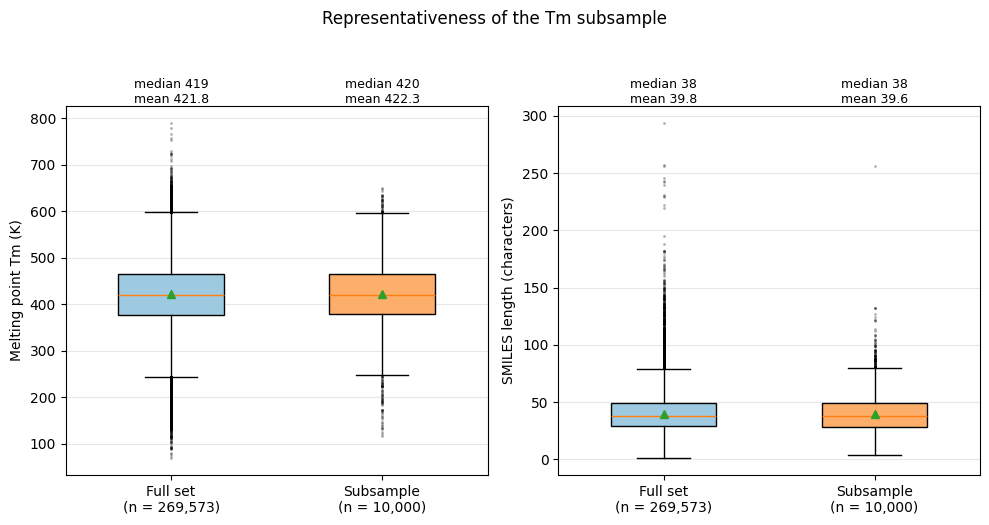

In [ ]:
import matplotlib.pyplot as plt                                                  #LIBRARY FOR PLOTTING

data_sets = [("Full set", tm), ("Subsample", tm_final)]                          #THE TWO DATA SETS BEING COMPARED
measures = [("Melting point Tm (K)", lambda d: d[tm_target]),
            ("SMILES length (characters)", lambda d: d["smiles"].str.len())]     #SMILES LENGTH IS A SIMPLE PROXY FOR MOLECULE SIZE

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (label, getter) in zip(axes, measures):
    vals = [getter(d).values for _, d in data_sets]
    bp = ax.boxplot(vals, tick_labels=[f"{n}\n(n = {len(v):,})" for (n, _), v in zip(data_sets, vals)],
                    showmeans=True, patch_artist=True, widths=0.5,
                    flierprops=dict(marker=".", markersize=2, alpha=0.3))        #SHOWS MEDIAN (LINE) AND MEAN (TRIANGLE)
    for patch, colour in zip(bp["boxes"], ["#9ecae1", "#fdae6b"]):
        patch.set_facecolor(colour)
    for i, v in enumerate(vals, start=1):
        ax.text(i, ax.get_ylim()[1], f"median {np.median(v):.0f}\nmean {np.mean(v):.1f}",
                ha="center", va="bottom", fontsize=9)                            #MEDIAN AND MEAN PRINTED ABOVE EACH BOX
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Representativeness of the Tm subsample", y=1.04)
plt.tight_layout()
plt.savefig("plots_Tm_subsample_check.png", dpi=150, bbox_inches="tight")
plt.show()


In [25]:
print("Duplicated molecules:", len(d), "| entries belonging to them:", int(d["count"].sum()))

g = df_tm.groupby("smiles")[tm_target].agg(["count", "min", "max"])
g = g[g["count"] > 1]
print("Tm duplicate spread: median", (g["max"] - g["min"]).median(), "K over", len(g), "molecules")

spread = g["max"] - g["min"]
print(spread.quantile([0.5, 0.75, 0.9, 0.95, 0.99]).round(2))
print("share of duplicated molecules with spread > 1 K:", round((spread > 1).mean(), 3), "| > 5 K:", round((spread > 5).mean(), 3))


g = df_tm.groupby("smiles").size()                                                   #NUMBER OF ENTRIES PER SMILES AFTER STEREO REMOVAL
dupes = g[g > 1]                                                                     #ONLY MOLECULES WITH MORE THAN ONE ENTRY
print("Molecules with duplicates:", len(dupes))
print("Entries belonging to them:", int(dupes.sum()))
print("Reduction in data set:", int(dupes.sum()) - len(dupes))                       #SHOULD EQUAL 3 572


Duplicated molecules: 88 | entries belonging to them: 195
Tm duplicate spread: median 0.014870129870161009 K over 2924 molecules
0.50     0.01
0.75     0.88
0.90     4.37
0.95    18.00
0.99    73.38
dtype: float64
share of duplicated molecules with spread > 1 K: 0.184 | > 5 K: 0.091
Molecules with duplicates: 2924
Entries belonging to them: 6496
Reduction in data set: 3572


       ΔHfus (kcal/mol)    Tm (K)
count           4501.00  10000.00
mean               6.66    422.26
std                5.85     64.33
min                0.01    116.15
5%                 1.25    327.15
50%                5.64    420.15
95%               14.84    530.15
max              106.86    649.82

Skewness: ΔHfus = 5.44 | Tm = -0.02

ΔHfus values more than 4 std from the mean: 39
                                                                                                                                                                                            smiles  dHfus [kcal/mol]
                                          CCCCCCCCCCCCCCCCCC(=O)OCC(OC(=O)CCCCCCCCCCCCCCCCC)C(OC(=O)CCCCCCCCCCCCCCCCC)C(OC(=O)CCCCCCCCCCCCCCCCC)C(COC(=O)CCCCCCCCCCCCCCCCC)OC(=O)CCCCCCCCCCCCCCCCC        106.859583
O=S(=O)(O)c1cc2c(O)c(c1)Cc1cc(S(=O)(=O)O)cc(c1O)Cc1cc(S(=O)(=O)O)cc(c1O)Cc1cc(S(=O)(=O)O)cc(c1O)Cc1cc(S(=O)(=O)O)cc(c1O)Cc1cc(S(=O)(=O)O)cc(c1O)Cc1cc(S(=O)(=O)O)cc(c1O)Cc1cc(S(=O)(=O)

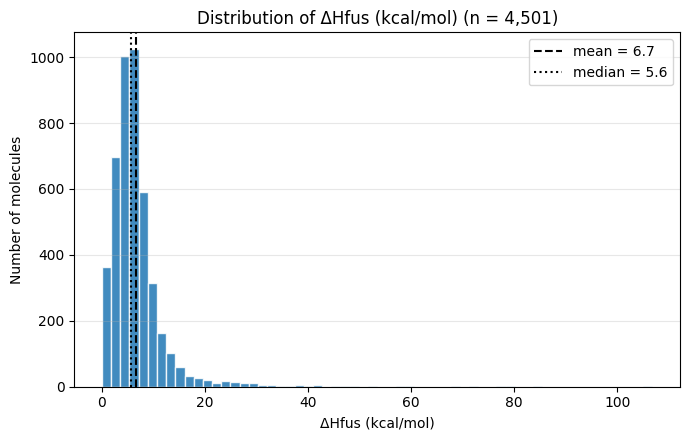

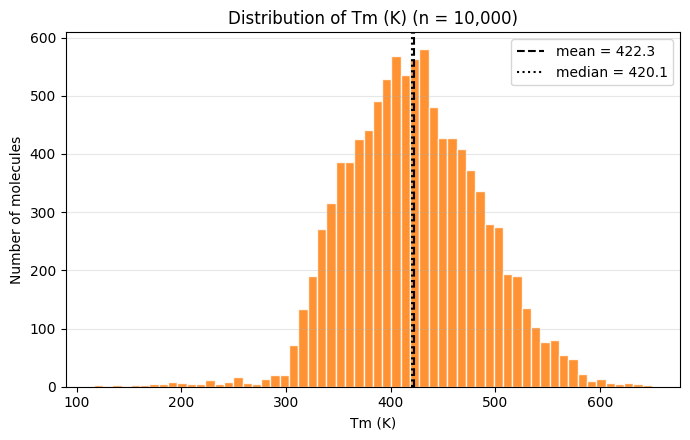

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

dh = pd.read_csv("RAW DATA/dHfus_clean.csv")                                      #FINAL ΔHfus DATA (WITH SMILES)
tm = pd.read_csv("RAW DATA/Tm_clean.csv")                                         #FINAL Tm SUBSAMPLE (WITH SMILES)
dh_vals = dh["dHfus [kcal/mol]"]
tm_vals = tm["Tm[K]"]

stats_tab = pd.DataFrame({
    "ΔHfus (kcal/mol)": dh_vals.describe(percentiles=[0.05, 0.5, 0.95]),
    "Tm (K)": tm_vals.describe(percentiles=[0.05, 0.5, 0.95])}).round(2)
print(stats_tab)                                                                  #SUMMARY TABLE FOR THE REPORT
print("\nSkewness: ΔHfus =", round(dh_vals.skew(), 2), "| Tm =", round(tm_vals.skew(), 2))     #POSITIVE = RIGHT-SKEWED

out = dh[np.abs(dh_vals - dh_vals.mean()) > 4 * dh_vals.std()]                    #MOLECULES MORE THAN 4 STANDARD DEVIATIONS FROM THE MEAN
print("\nΔHfus values more than 4 std from the mean:", len(out))
print(out.sort_values("dHfus [kcal/mol]", ascending=False).head(10).to_string(index=False))    #TOP 10 OUTLIERS FOR INSPECTION

def distribution_plot(vals, xlabel, colour, filename):                            #ONE HISTOGRAM WITH MEAN AND MEDIAN MARKED
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.hist(vals, bins=60, color=colour, alpha=0.85, edgecolor="white")
    ax.axvline(vals.mean(), color="k", ls="--", label=f"mean = {vals.mean():.1f}")
    ax.axvline(vals.median(), color="k", ls=":", label=f"median = {vals.median():.1f}")
    ax.set_xlabel(xlabel); ax.set_ylabel("Number of molecules")
    ax.set_title(f"Distribution of {xlabel} (n = {len(vals):,})")
    ax.legend(); ax.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.savefig(filename, dpi=150); plt.show()

distribution_plot(dh_vals, "ΔHfus (kcal/mol)", "#1f77b4", "plots_dist_dHfus.png")  #FIGURE 1: FUSION ENTHALPY
distribution_plot(tm_vals, "Tm (K)", "#ff7f0e", "plots_dist_Tm.png")               #FIGURE 2: MELTING POINT


In [ ]:
import pandas as pd, numpy as np

dh = pd.read_csv("RAW DATA/dHfus_clean.csv")["dHfus [kcal/mol]"]                  #FINAL ΔHfus DATA
threshold = dh.mean() + 4 * dh.std()                                              #FOUR STANDARD DEVIATIONS ABOVE THE MEAN
trimmed = dh[dh < threshold]                                                       #DATA WITHOUT THE EXTREME VALUES

print(f"Threshold (mean + 4 std): {threshold:.2f} kcal/mol")
print(f"Molecules above threshold: {(dh >= threshold).sum()} of {len(dh)} ({100*(dh >= threshold).mean():.2f}%)")
print(f"\n{'':22s}{'all data':>12s}{'without outliers':>20s}")
print(f"{'count':22s}{len(dh):>12d}{len(trimmed):>20d}")
print(f"{'mean (kcal/mol)':22s}{dh.mean():>12.2f}{trimmed.mean():>20.2f}")
print(f"{'median (kcal/mol)':22s}{dh.median():>12.2f}{trimmed.median():>20.2f}")
print(f"{'std (kcal/mol)':22s}{dh.std():>12.2f}{trimmed.std():>20.2f}")
print(f"{'skewness':22s}{dh.skew():>12.2f}{trimmed.skew():>20.2f}")
print(f"{'max (kcal/mol)':22s}{dh.max():>12.2f}{trimmed.max():>20.2f}")

import pandas as pd, numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem.rdMolDescriptors import CalcMolFormula

dh_full = pd.read_csv("RAW DATA/dHfus_clean.csv")                                     #FINAL ΔHfus DATA WITH SMILES
top10 = dh_full.sort_values("dHfus [kcal/mol]", ascending=False).head(10).copy()      #TEN HIGHEST FUSION ENTHALPIES
mols_top = top10["smiles"].apply(Chem.MolFromSmiles)
top10["formula"] = mols_top.apply(CalcMolFormula)                                      #MOLECULAR FORMULA
top10["MW (g/mol)"] = mols_top.apply(Descriptors.MolWt).round(1)                       #MOLECULAR WEIGHT
print(top10[["dHfus [kcal/mol]", "formula", "MW (g/mol)"]].round(2).to_string(index=False))
print("\nMedian MW of the whole data set:", round(dh_full["smiles"].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s))).median(), 1))


Threshold (mean + 4 std): 30.07 kcal/mol
Molecules above threshold: 39 of 4501 (0.87%)

                          all data    without outliers
count                         4501                4462
mean (kcal/mol)               6.66                6.30
median (kcal/mol)             5.64                5.61
std (kcal/mol)                5.85                4.19
skewness                      5.44                1.93
max (kcal/mol)              106.86               29.40
 dHfus [kcal/mol]     formula  MW (g/mol)
           106.86 C114H218O12      1781.0
            83.80 C56H48O32S8      1489.5
            79.30    C100H202      1404.7
            77.72 C102H194O12      1612.7
            72.97  C95H182O10      1484.5
            71.94     C96H192      1346.6
            68.76   C20H33F9O       460.5
            59.27   C76H146O8      1188.0
            57.41  C75H142O10      1204.0
            52.63     C72H144      1009.9

Median MW of the whole data set: 222.5


In [ ]:
import pandas as pd, numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors

d = pd.read_csv("RAW DATA/dHfus_clean.csv")                                       #FINAL ΔHfus DATA
target = "dHfus [kcal/mol]"
d["MW"] = d["smiles"].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))    #MOLECULAR WEIGHT OF EVERY MOLECULE

lo, hi = d[target].quantile(0.05), d[target].quantile(0.95)                        #5TH AND 95TH PERCENTILE OF ΔHfus
bulk = d[(d[target] >= lo) & (d[target] <= hi)]                                    #MOLECULES IN THE BULK OF THE DISTRIBUTION
thr = d[target].mean() + 4 * d[target].std()
outl = d[d[target] > thr]                                                          #MOLECULES MORE THAN 4 STD ABOVE THE MEAN

def mw_summary(x):                                                                 #MW SUMMARY FOR ONE GROUP OF MOLECULES
    return pd.Series({"n": len(x), "min": x.min(), "5th pct": x.quantile(0.05), "median": x.median(),
                      "mean": x.mean(), "95th pct": x.quantile(0.95), "max": x.max()})

table = pd.DataFrame({
    f"ΔHfus {lo:.2f}-{hi:.2f} (5th-95th pct)": mw_summary(bulk["MW"]),
    f"ΔHfus > {thr:.1f} (outliers)": mw_summary(outl["MW"]),
    "All molecules": mw_summary(d["MW"])}).round(1)
print(table)                                                                       #MOLECULAR WEIGHT RANGES FOR THE REPORT

print(f"\nBulk band (ΔHfus {lo:.2f}-{hi:.2f}): fraction with MW > 500 = {100*(bulk['MW'] > 500).mean():.1f}% | max MW = {bulk['MW'].max():.1f}")   #REUSES bulk FROM THE EARLIER MW CELL
print(f"Whole data set: fraction with MW > 500 = {100*(d['MW'] > 500).mean():.1f}%")


          ΔHfus 1.25-14.84 (5th-95th pct)  ΔHfus > 30.1 (outliers)  \
n                                  4052.0                     39.0   
min                                  17.0                    460.5   
5th pct                              92.1                    557.4   
median                              221.5                    731.4   
mean                                244.3                    924.8   
95th pct                            480.0                   1631.3   
max                                1502.6                   1783.0   

          All molecules  
n                4501.0  
min                16.0  
5th pct            88.1  
median            222.5  
mean              255.2  
95th pct          532.7  
max              1783.0  

Bulk band (ΔHfus 1.25-14.84): fraction with MW > 500 = 4.2% | max MW = 1502.6
Whole data set: fraction with MW > 500 = 6.1%


In [ ]:
import pandas as pd, numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors

d = pd.read_csv("RAW DATA/dHfus_clean.csv")                                       #FINAL ΔHfus DATA
target = "dHfus [kcal/mol]"
d["MW"] = d["smiles"].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))    #MOLECULAR WEIGHT OF EVERY MOLECULE

thr = d[target].mean() + 4 * d[target].std()                                       #FOUR STANDARD DEVIATIONS ABOVE THE MEAN
outl = d[d[target] > thr]                                                          #THE 39 OUTLIERS

print(f"Outliers: {len(outl)}")
print(f"MW of outliers:  mean = {outl['MW'].mean():.1f} | median = {outl['MW'].median():.1f} | min = {outl['MW'].min():.1f} | max = {outl['MW'].max():.1f}")
print(f"Outliers with MW > 500:  {(outl['MW'] > 500).sum()} of {len(outl)}")
print(f"Outliers with MW > 1000: {(outl['MW'] > 1000).sum()} of {len(outl)}")
print(f"MW of whole set: mean = {d['MW'].mean():.1f} | median = {d['MW'].median():.1f}")


Outliers: 39
MW of outliers:  mean = 924.8 | median = 731.4 | min = 460.5 | max = 1783.0
Outliers with MW > 500:  38 of 39
Outliers with MW > 1000: 15 of 39
MW of whole set: mean = 255.2 | median = 222.5


In [23]:
import pandas as pd
full = pd.read_csv("RAW DATA/Tm_clean_full.csv"); sub = pd.read_csv("RAW DATA/Tm_clean.csv")
print(len(full), list(full.columns), sub["smiles"].isin(full["smiles"]).mean())

269573 ['smiles', 'Tm[K]'] 1.0
